<a href="https://colab.research.google.com/github/ginsr/My-Coding-Repository/blob/main/Case_Study_Preparing_Data_for_Analysis_Gina_Salsabila_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preparing Data for Analysis



# Task 1 — Data Understanding & Exploratory Data Analysis

## Instruksi

Lakukan eksplorasi awal terhadap dataset. Minimal yang harus ditampilkan:
1. Dataset Overview
- Shape dataset
- Data type tiap kolom
- Statistik deskriptif

2. Duplicate Check
- Identifikasi jumlah data duplikat
- Lakukan handling yang sesuai

## Dataset Overview

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.options.display.float_format = '{:,.2f}'.format
import seaborn as sns
from scipy.stats import mstats
from sklearn.preprocessing import LabelEncoder

In [ ]:
df_employee = pd.read_csv("/content/employee_performance_assignment_dirty.csv")

df_employee.shape

(1248, 14)

In [ ]:
df_employee.dtypes

,0
employee_id,object
department,object
job_role,object
education_level,object
work_mode,object
city,object
age,int64
years_experience,int64
monthly_salary,float64
training_hours,float64


In [ ]:
df_employee.head(10)

,employee_id,department,job_role,education_level,work_mode,city,age,years_experience,monthly_salary,training_hours,projects_completed,overtime_hours,satisfaction_score,performance_category
0,EMP00001,IT,Sales Executive,High School,Hybrid,Surabaya,23,28,"19,537,826.00",17.00,19,22,2.60,Low
1,EMP00002,IT,Software Engineer,Bachelor,Hybrid,Jakarta,30,32,"14,951,456.00",25.00,19,14,1.20,Low
2,EMP00003,Sales,Product Manager,Bachelor,Remote,Bandung,53,16,"20,549,508.00",49.00,3,2,1.30,Low
3,EMP00004,IT,Software Engineer,High School,Remote,Yogyakarta,23,20,"11,822,392.00",61.00,16,7,3.90,Low
4,EMP00005,IT,Product Manager,Master,Onsite,Jakarta,49,33,NaN,27.00,2,33,5.00,Low
5,EMP00006,Operations,Business Analyst,Diploma,Onsite,Surabaya,24,5,NaN,75.00,2,10,1.60,Medium
6,EMP00007,it,HR Officer,Bachelor,Hybrid,Jakarta,39,15,"24,225,579.00",27.00,12,30,3.00,Medium
7,EMP00008,Marketing,Finance Analyst,Master,Onsite,Semarang,47,16,"29,371,590.00",14.00,7,11,4.70,High
8,EMP00009,HR,Customer Success,Bachelor,Onsite,Yogyakarta,22,25,"20,116,244.00",56.00,17,12,4.30,High
9,EMP00010,HR,Software Engineer,Master,Remote,Medan,22,27,"17,711,857.00",3.00,3,11,2.10,Medium


In [ ]:
df_employee.describe()

,age,years_experience,monthly_salary,training_hours,projects_completed,overtime_hours,satisfaction_score
count,"1,248.00","1,248.00","1,149.00","1,149.00","1,248.00","1,248.00","1,149.00"
mean,40.07,17.28,"18,875,833.79",41.11,9.80,20.33,3.04
std,12.29,9.81,"16,338,244.69",41.12,5.73,20.10,1.14
min,21.00,0.00,"5,000,706.00",0.00,0.00,0.00,1.00
25%,30.00,9.00,"11,684,058.00",18.00,5.00,9.00,2.10
50%,40.00,18.00,"17,951,594.00",38.00,10.00,19.00,3.00
75%,49.00,26.00,"23,778,599.00",59.00,15.00,30.00,4.00
max,120.00,34.00,"250,000,000.00",500.00,19.00,250.00,5.00


## Distribusi Data

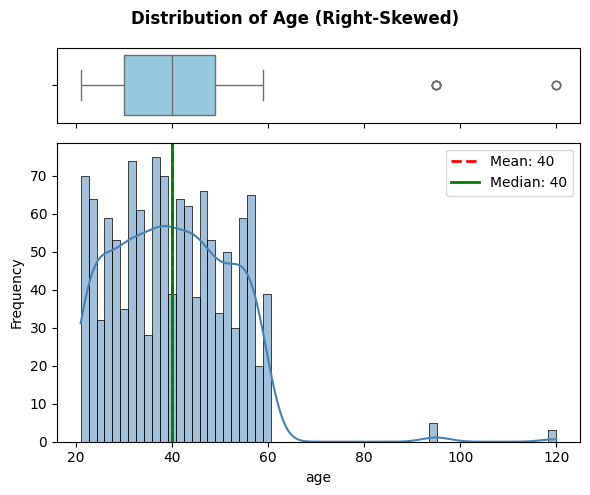

In [ ]:
fig, (ax_box, ax_hist)=plt.subplots(2, 1, figsize=(6, 5), sharex=True, gridspec_kw={"height_ratios" : (0.2, 0.8)})

fig.suptitle(f'Distribution of Age (Right-Skewed)', fontsize=12, fontweight='bold')

sns.boxplot(x=df_employee['age'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(x=df_employee['age'], kde=True, ax=ax_hist, bins=60, color='steelblue')
ax_hist.set_xlabel('age')
ax_hist.set_ylabel('Frequency')

ax_hist.axvline(df_employee['age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_employee['age'].mean():,.0f}')
ax_hist.axvline(df_employee['age'].median(), color='green', linestyle="-", linewidth=2, label=f'Median: {df_employee['age'].median():,.0f}')

plt.tight_layout()
ax_hist.legend()
plt.show()

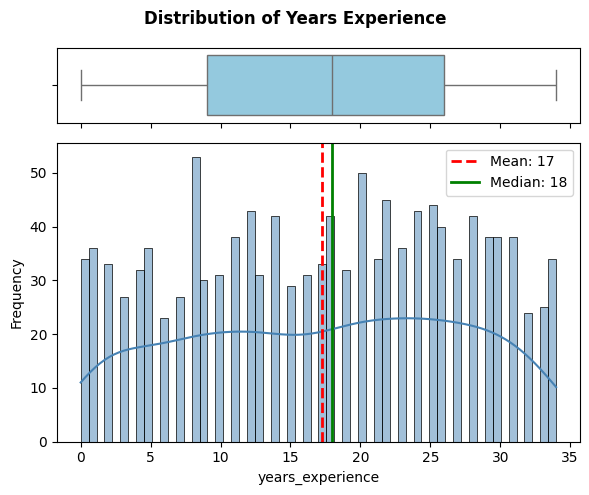

In [ ]:
fig, (ax_box, ax_hist)=plt.subplots(2, 1, figsize=(6, 5), sharex=True, gridspec_kw={"height_ratios" : (0.2, 0.8)})

fig.suptitle(f'Distribution of Years Experience', fontsize=12, fontweight='bold')

sns.boxplot(x=df_employee['years_experience'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(x=df_employee['years_experience'], kde=True, ax=ax_hist, bins=60, color='steelblue')
ax_hist.set_xlabel('years_experience')
ax_hist.set_ylabel('Frequency')

ax_hist.axvline(df_employee['years_experience'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_employee['years_experience'].mean():,.0f}')
ax_hist.axvline(df_employee['years_experience'].median(), color='green', linestyle="-", linewidth=2, label=f'Median: {df_employee['years_experience'].median():,.0f}')

plt.tight_layout()
ax_hist.legend()
plt.show()

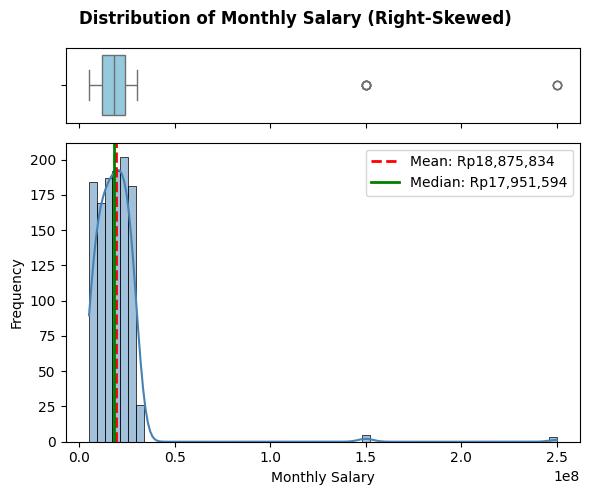

In [ ]:
fig, (ax_box, ax_hist)=plt.subplots(2, 1, figsize=(6, 5), sharex=True, gridspec_kw={"height_ratios" : (0.2, 0.8)})

fig.suptitle(f'Distribution of Monthly Salary (Right-Skewed)', fontsize=12, fontweight='bold')

sns.boxplot(x=df_employee['monthly_salary'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(x=df_employee['monthly_salary'], kde=True, ax=ax_hist, bins=60, color='steelblue')
ax_hist.set_xlabel('Monthly Salary')
ax_hist.set_ylabel('Frequency')

ax_hist.axvline(df_employee['monthly_salary'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: Rp{df_employee['monthly_salary'].mean():,.0f}')
ax_hist.axvline(df_employee['monthly_salary'].median(), color='green', linestyle="-", linewidth=2, label=f'Median: Rp{df_employee['monthly_salary'].median():,.0f}')

plt.tight_layout()
ax_hist.legend()
plt.show()

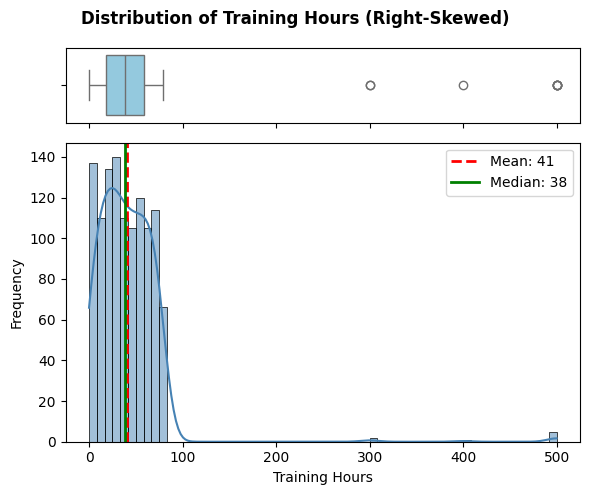

In [ ]:
fig, (ax_box, ax_hist)=plt.subplots(2, 1, figsize=(6, 5), sharex=True, gridspec_kw={"height_ratios" : (0.2, 0.8)})

fig.suptitle(f'Distribution of Training Hours (Right-Skewed)', fontsize=12, fontweight='bold')

sns.boxplot(x=df_employee['training_hours'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(x=df_employee['training_hours'], kde=True, ax=ax_hist, bins=60, color='steelblue')
ax_hist.set_xlabel('Training Hours')
ax_hist.set_ylabel('Frequency')

ax_hist.axvline(df_employee['training_hours'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_employee['training_hours'].mean():,.0f}')
ax_hist.axvline(df_employee['training_hours'].median(), color='green', linestyle="-", linewidth=2, label=f'Median: {df_employee['training_hours'].median():,.0f}')

plt.tight_layout()
ax_hist.legend()
plt.show()

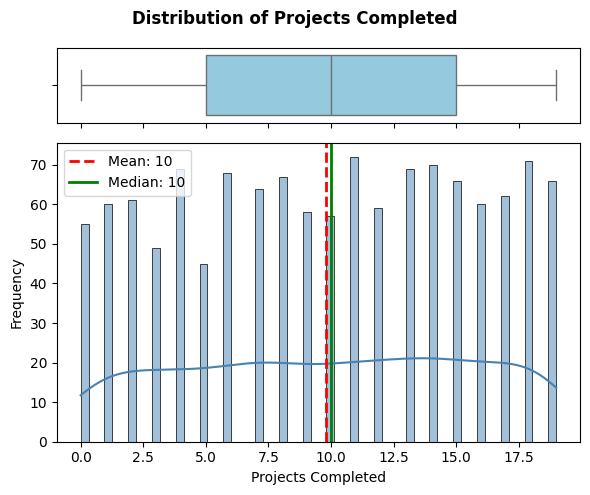

In [ ]:
fig, (ax_box, ax_hist)=plt.subplots(2, 1, figsize=(6, 5), sharex=True, gridspec_kw={"height_ratios" : (0.2, 0.8)})

fig.suptitle(f'Distribution of Projects Completed', fontsize=12, fontweight='bold')

sns.boxplot(x=df_employee['projects_completed'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(x=df_employee['projects_completed'], kde=True, ax=ax_hist, bins=60, color='steelblue')
ax_hist.set_xlabel('Projects Completed')
ax_hist.set_ylabel('Frequency')

ax_hist.axvline(df_employee['projects_completed'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_employee['projects_completed'].mean():,.0f}')
ax_hist.axvline(df_employee['projects_completed'].median(), color='green', linestyle="-", linewidth=2, label=f'Median: {df_employee['projects_completed'].median():,.0f}')

plt.tight_layout()
ax_hist.legend()
plt.show()

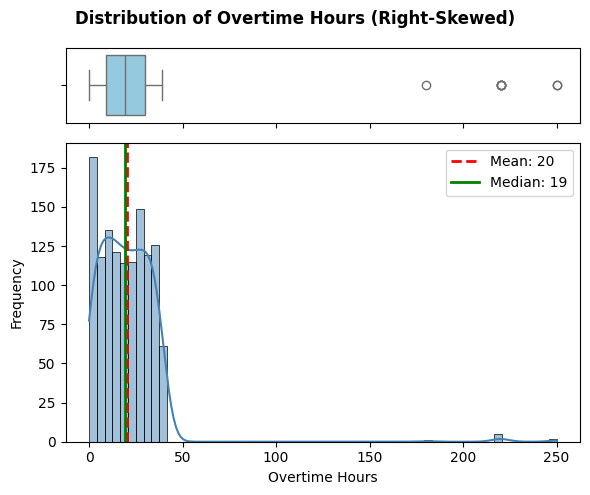

In [ ]:
fig, (ax_box, ax_hist)=plt.subplots(2, 1, figsize=(6, 5), sharex=True, gridspec_kw={"height_ratios" : (0.2, 0.8)})

fig.suptitle(f'Distribution of Overtime Hours (Right-Skewed)', fontsize=12, fontweight='bold')

sns.boxplot(x=df_employee['overtime_hours'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(x=df_employee['overtime_hours'], kde=True, ax=ax_hist, bins=60, color='steelblue')
ax_hist.set_xlabel('Overtime Hours')
ax_hist.set_ylabel('Frequency')

ax_hist.axvline(df_employee['overtime_hours'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_employee['overtime_hours'].mean():,.0f}')
ax_hist.axvline(df_employee['overtime_hours'].median(), color='green', linestyle="-", linewidth=2, label=f'Median: {df_employee['overtime_hours'].median():,.0f}')

plt.tight_layout()
ax_hist.legend()
plt.show()

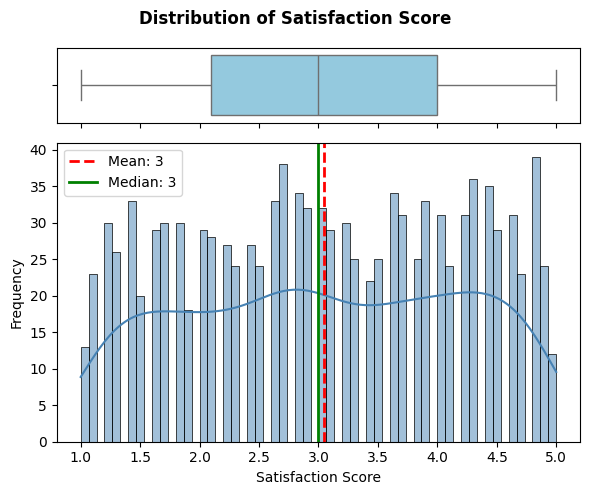

In [ ]:
fig, (ax_box, ax_hist)=plt.subplots(2, 1, figsize=(6, 5), sharex=True, gridspec_kw={"height_ratios" : (0.2, 0.8)})

fig.suptitle(f'Distribution of Satisfaction Score', fontsize=12, fontweight='bold')

sns.boxplot(x=df_employee['satisfaction_score'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(x=df_employee['satisfaction_score'], kde=True, ax=ax_hist, bins=60, color='steelblue')
ax_hist.set_xlabel('Satisfaction Score')
ax_hist.set_ylabel('Frequency')

ax_hist.axvline(df_employee['satisfaction_score'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_employee['satisfaction_score'].mean():,.0f}')
ax_hist.axvline(df_employee['satisfaction_score'].median(), color='green', linestyle="-", linewidth=2, label=f'Median: {df_employee['satisfaction_score'].median():,.0f}')

plt.tight_layout()
ax_hist.legend()
plt.show()

## Duplicate Check

In [ ]:
duplicate_count = df_employee.duplicated().sum()
print(f"Jumlah Baris Duplikat: {duplicate_count}")

Jumlah Baris Duplikat: 43


In [ ]:
df_employee = df_employee.drop_duplicates()

In [ ]:
df_employee.shape

(1205, 14)

## Insight

Berikan minimal:
- 3 insight dari kolom numerik
- 3 insight dari kolom kategorikal

A. Insight Kolom Numerik
- Pada kolom monthly_salary terdapat nilai outlier ekstrem yang mencapai 250 juta, padahal mean-nya hanya 18,8 juta dan mediannya 17,9 juta. Ada kemungkinan human error dibagian ini.
- Pada kolom age juga ada nilai outlier yang tidak realistis yaitu 120 tahun, dengan mean dan median usia 40 tahun. Ada kemungkinan human error dibagian ini.
- Pada kolom training_hours dan overtime_hour juga terdapat outlier yang terlalu ekstrem atau tidak wajar. Yaitu 500 jam untuk training_hours dan 250 jam untuk overtime_hours

B. Insight Kolom Kategorikal
- Ada keanehan pada kolom department dan job role. Contoh pada baris pertama karyawan ini berasal dari department IT namun job role-nya Saled Executive, maka diperlukan validasi ulang
- Kantor ini memiliki work mode yang beragam mulai dari Hybrid, Remote, dan Onsite
- Pada baris ke 7 kolom department penulisan IT tidak menggunakan huruf kapital, hal ini akan menimbulkan rancu saat ada analisis nama department

# Task 2 — Outlier Analysis & Handling

## Instruksi

Lakukan analisis outlier menggunakan metode IQR.
Untuk setiap kolom numerik:
1. Hitung
```
Q1
Q3
IQR
Lower Bound
Upper Bound
```

2. Identifikasi jumlah outlier
3. Lakukan handling outlier menggunakan metode yang menurut Anda paling sesuai: Winsorization

In [ ]:
numeric_cols = df_employee.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
  Q1 = df_employee[col].quantile(0.25)
  Q3 = df_employee[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = ((df_employee[col] < lower_bound) | (df_employee[col] > upper_bound)).sum()

  print(f"Kolom: {col}")
  print(f"Q1: {Q1} | Q3: {Q3} | IQR: {IQR}")
  print(f"Lower Bound: {lower_bound} | Upper Bound: {upper_bound}")
  print(f"Jumlah Outliers: {outliers}\n")

Kolom: age
Q1: 30.0 | Q3: 49.0 | IQR: 19.0
Lower Bound: 1.5 | Upper Bound: 77.5
Jumlah Outliers: 8

Kolom: years_experience
Q1: 9.0 | Q3: 26.0 | IQR: 17.0
Lower Bound: -16.5 | Upper Bound: 51.5
Jumlah Outliers: 0

Kolom: monthly_salary
Q1: 11757582.5 | Q3: 23795654.0 | IQR: 12038071.5
Lower Bound: -6299524.75 | Upper Bound: 41852761.25
Jumlah Outliers: 8

Kolom: training_hours
Q1: 18.0 | Q3: 59.0 | IQR: 41.0
Lower Bound: -43.5 | Upper Bound: 120.5
Jumlah Outliers: 8

Kolom: projects_completed
Q1: 5.0 | Q3: 15.0 | IQR: 10.0
Lower Bound: -10.0 | Upper Bound: 30.0
Jumlah Outliers: 0

Kolom: overtime_hours
Q1: 9.0 | Q3: 30.0 | IQR: 21.0
Lower Bound: -22.5 | Upper Bound: 61.5
Jumlah Outliers: 8

Kolom: satisfaction_score
Q1: 2.1 | Q3: 4.0 | IQR: 1.9
Lower Bound: -0.7499999999999996 | Upper Bound: 6.85
Jumlah Outliers: 0



In [ ]:
# Winsorization
target_outlier_cols = ['age', 'monthly_salary', 'training_hours', 'overtime_hours']

for col in target_outlier_cols:
  Q1 = df_employee[col].quantile(0.05)
  Q3 = df_employee[col].quantile(0.95)

  df_employee[col] = np.where(df_employee[col] < Q1, Q1, df_employee[col])
  df_employee[col] = np.where(df_employee[col] > Q3, Q3, df_employee[col])

In [ ]:
df_employee[numeric_cols].describe()

,age,years_experience,monthly_salary,training_hours,projects_completed,overtime_hours,satisfaction_score
count,"1,205.00","1,205.00","1,108.00","1,109.00","1,205.00","1,205.00","1,108.00"
mean,39.69,17.29,"17,787,329.01",38.27,9.83,19.17,3.04
std,11.11,9.86,"7,142,009.56",23.24,5.71,11.71,1.15
min,22.00,0.00,"6,180,122.05",2.00,0.00,1.00,1.00
25%,30.00,9.00,"11,757,582.50",18.00,5.00,9.00,2.10
50%,40.00,18.00,"17,938,913.00",37.00,10.00,19.00,3.00
75%,49.00,26.00,"23,795,654.00",59.00,15.00,30.00,4.00
max,58.00,34.00,"29,035,888.80",76.00,19.00,38.00,5.00


# Task 3 — Missing Value Analysis & Handling

# Instruksi

Lakukan investigasi missing value.

Missing Value Analysis

1. Tampilkan:

`df.isnull().sum()` dan persentase missing value.

2. Handling Missing Value
Gunakan metode yang sesuai:
- Numerical
Contoh: Median
- Categorical
Contoh: Mode

Jelaskan alasan pemilihan metode.

In [ ]:
missing_value = df_employee.isnull().sum()
missing_value_percentage = (df_employee.isnull().mean() * 100).round(2)

df_missing_investigation = pd.DataFrame({'Jumlah Missing Value': missing_value, 'Persentase (%)': missing_value_percentage})

print(df_missing_investigation)

                      Jumlah Missing Value  Persentase (%)
employee_id                              0            0.00
department                               0            0.00
job_role                                 0            0.00
education_level                         98            8.13
work_mode                                0            0.00
city                                     0            0.00
age                                      0            0.00
years_experience                         0            0.00
monthly_salary                          97            8.05
training_hours                          96            7.97
projects_completed                       0            0.00
overtime_hours                           0            0.00
satisfaction_score                      97            8.05
performance_category                     0            0.00


In [ ]:
# education_level
df_employee['education_level'] = df_employee['education_level'].fillna('Not Specified')

In [ ]:
#monthly_salary
df_employee['monthly_salary'] = df_employee['monthly_salary'].fillna(df_employee['monthly_salary'].median())

In [ ]:
#training_hours
df_employee['training_hours'] = df_employee['training_hours'].fillna(df_employee['training_hours'].median())

In [ ]:
#satisfaction_score
df_employee['satisfaction_score'] = df_employee['satisfaction_score'].fillna(df_employee['satisfaction_score'].median())

In [ ]:
print("\nSisa Missing Value:")
print(df_employee.isnull().sum())


Sisa Missing Value:
employee_id             0
department              0
job_role                0
education_level         0
work_mode               0
city                    0
age                     0
years_experience        0
monthly_salary          0
training_hours          0
projects_completed      0
overtime_hours          0
satisfaction_score      0
performance_category    0
dtype: int64


1.   Alasan menggunakan metode median untuk kolom monthly_salary, training_hours, dan satisfication_score dikarenakan median tidak akan berubah/terpengaruh oleh nilai ekstrim atau outlier, sehingga hasil penarikan data tidak akan menyimpang dari kondisi data sebenarnya.
2.   Alasan kolom education_level diisi dengan "Not Specified" dikarenakan isinya bukan data numerik dan juga latar belakang pendidikan seseorang bukanlah data yang bisa ditebak. Kemungkinan kosongnya data disebabkan 'human error' atau terlewat dalam pencatatan.



# Task 4 — Data Encoding

# Instruksi

Ubah data kategorikal menjadi format numerik yang dapat digunakan untuk analisis lebih lanjut.

A. Label Encoding
1. Lakukan Label Encoding pada kolom: `performance_category`
2. Tampilkan:
- Penjelasan terkait mapping yang digunakan
- Hasil sebelum dan sesudah encoding

B. One Hot Encoding
1. Pilih minimal 2 kolom kategorikal dari daftar berikut:
* department
* work_mode
* city
* education_level
Lakukan One Hot Encoding pada kolom yang dipilih.
2. Tampilkan:
- Kolom sebelum encoding
- Kolom hasil encoding
- Jumlah kolom yang bertambah setelah encoding

**A. Label Encoding**

In [ ]:
print("---SEBELUM LABEL ENCODING---")
print(df_employee['performance_category'])

---SEBELUM LABEL ENCODING---
0          Low
1          Low
2          Low
3          Low
4          Low
         ...  
1203      High
1211    Medium
1222    Medium
1227       Low
1237    Medium
Name: performance_category, Length: 1205, dtype: object


In [ ]:
mapping = {'Low': 0, 'Medium': 1, 'High': 2}

df_employee['performance_category_encoded'] = df_employee['performance_category'].map(mapping)

print("\n---SESUDAH LABEL ENCODING---")
print(df_employee[['performance_category', 'performance_category_encoded']])


---SESUDAH LABEL ENCODING---
     performance_category  performance_category_encoded
0                     Low                             0
1                     Low                             0
2                     Low                             0
3                     Low                             0
4                     Low                             0
...                   ...                           ...
1203                 High                             2
1211               Medium                             1
1222               Medium                             1
1227                  Low                             0
1237               Medium                             1

[1205 rows x 2 columns]


**B. One Hot Encoding**

In [ ]:
print(f"Jumlah total kolom sebelum One Hot Encoding: {df_employee.shape[1]}")

print("\n---KOLOM SEBELUM ONE HOT ENCODING---")
print(df_employee[['department', 'work_mode']])

Jumlah total kolom sebelum One Hot Encoding: 15

---KOLOM SEBELUM ONE HOT ENCODING---
     department work_mode
0            IT    Hybrid
1            IT    Hybrid
2         Sales    Remote
3            IT    Remote
4            IT    Onsite
...         ...       ...
1203         HR    Remote
1211      Sales    Onsite
1222      Sales    Hybrid
1227  Marketing    Onsite
1237         HR    Remote

[1205 rows x 2 columns]


In [ ]:
df_employee = pd.get_dummies(df_employee, columns=['department', 'work_mode'], drop_first=True, dtype=int)

print("\n---KOLOM HASIL ONE HOT ENCODING---")
print(df_employee.filter(like='department_'))
print(df_employee.filter(like='work_mode_'))

jumlah_kolom_baru =df_employee.shape[1]
print(f"\nJumlah Total Kolom Setelah One Hot Encoding: {jumlah_kolom_baru}")


---KOLOM HASIL ONE HOT ENCODING---
      department_HR  department_IT  department_Marketing  \
0                 0              1                     0   
1                 0              1                     0   
2                 0              0                     0   
3                 0              1                     0   
4                 0              1                     0   
...             ...            ...                   ...   
1203              1              0                     0   
1211              0              0                     0   
1222              0              0                     0   
1227              0              0                     1   
1237              1              0                     0   

      department_Operations  department_Sales  department_it  
0                         0                 0              0  
1                         0                 0              0  
2                         0                 1         

# Task 5 — Selecting, Filtering & Sorting Data

# Instruksi

Lakukan selecting, filtering, dan sorting sesuai kebutuhan analisis. Minimal yang harus dilakukan:

A. Filtering
1. Tampilkan data karyawan dengan kondisi tertentu (contoh: performa tertentu atau departemen tertentu).

B. Sorting
1. Urutkan data berdasarkan kriteria tertentu (contoh: masa kerja terlama atau gaji tertinggi).

C. Insight
1. Berikan insight dari hasil eksplorasi data yang difilter dan disortir tersebut.

In [ ]:
filtered_all_df = df_employee[df_employee['performance_category'] == 'High']

print("--- KARYAWAN DENGAN PERFORMA KERJA 'HIGH'---")
print(filtered_all_df[['employee_id', 'performance_category']].head(10))
print(f"Jumlah Karyawan dengan performa 'HIGH': {len(filtered_all_df)} orang")

--- KARYAWAN DENGAN PERFORMA KERJA 'HIGH'---
   employee_id performance_category
7     EMP00008                 High
8     EMP00009                 High
10    EMP00011                 High
16    EMP00017                 High
18    EMP00019                 High
19    EMP00020                 High
21    EMP00022                 High
24    EMP00025                 High
25    EMP00026                 High
27    EMP00028                 High
Jumlah Karyawan dengan performa 'HIGH': 370 orang


In [ ]:
sorted_all_df= df_employee.sort_values(by='years_experience', ascending=False)

print("--- DATA MASA KERJA KARYAWAN DARI TERTINGGI HINGGA TERENDAH ---")
print(sorted_all_df[['employee_id', 'years_experience']])

--- DATA MASA KERJA KARYAWAN DARI TERTINGGI HINGGA TERENDAH ---
    employee_id  years_experience
353    EMP00354                34
378    EMP00379                34
320    EMP00321                34
417    EMP00418                34
440    EMP00441                34
..          ...               ...
359    EMP00360                 0
410    EMP00411                 0
389    EMP00390                 0
370    EMP00371                 0
290    EMP00291                 0

[1205 rows x 2 columns]


**INSIGHT**

*   Dari hasil filter data terdapat 370 karyawan yang memiliki performa kerja 'High'.
*   Berdasarkan data perusahaan, masa kerja karywan tercatat paling tinggi selama 34 tahun dan paling rendah 0 tahun.





# Task 6 — Group By Analysis

# Instruksi

Gunakan `groupby` dan aggregation (`sum`, `mean`, `count`, `max`, `min`) untuk menjawab pertanyaan analisis.

A. Aggregation
1. Tampilkan hasil aggregasi berdasarkan kategori tertentu. Contoh: rata-rata performa berdasarkan departemen, atau jumlah karyawan per kota.
2. Gunakan minimal 3 fungsi aggregasi yang berbeda.

B. Insight
1. Berikan insight yang relevan dari hasil aggregasi tersebut.

In [ ]:
multi_groupby_df = df_employee.groupby(['years_experience'])['monthly_salary'].agg(['mean', 'max', 'min']).reset_index()

multi_groupby_df.columns = ['Years Experience', 'Rata-Rata Gaji', 'Gaji Tertinggi', 'Gaji Terendah']

print("--- AGREGASI GAJI BERDASARKAN MASA KERJA ---")
print(multi_groupby_df)

--- AGREGASI GAJI BERDASARKAN MASA KERJA ---
    Years Experience  Rata-Rata Gaji  Gaji Tertinggi  Gaji Terendah
0                  0   15,348,299.22   27,103,343.00   6,180,122.05
1                  1   17,151,671.82   29,035,888.80   6,180,122.05
2                  2   18,237,761.47   29,035,888.80   6,180,122.05
3                  3   16,621,041.40   29,035,888.80   6,180,122.05
4                  4   16,464,902.50   29,035,888.80   6,180,122.05
5                  5   18,763,617.92   29,035,888.80   6,180,122.05
6                  6   19,152,201.67   29,035,888.80   7,091,061.00
7                  7   16,164,295.29   29,035,888.80   6,180,122.05
8                  8   18,120,989.20   29,035,888.80   6,180,122.05
9                  9   18,608,372.98   29,035,888.80   6,510,824.00
10                10   19,153,219.52   29,035,888.80   6,180,122.05
11                11   16,892,690.18   29,035,888.80   6,180,122.05
12                12   19,508,665.06   29,035,888.80   6,484,752.00
13 

**INSIGHT**
* Rentang gaji maksimum dan minimum angkanya cenderung konstan. Untuk gaji tertinggi dikisaran 27 jt - 28 jt dan gaji terendah berada di rentang 6 jt - 7 jt.
*   Tidak ada kenaikan gaji yang terjadi walau masa kerjanya telah mencapai puluhan tahun.
*   Variasi rata-rata gaji yang lebih luas rentangnya mungkin dipengaruhi faktor lain seperti kompensasi perusahaan terhadap *overtime hours* atau *job role*.









# Task 7 — Datetime Manipulation

# Instruksi

Lakukan manipulasi pada kolom tanggal/waktu (datetime) dalam dataset.

A. Ekstraksi
1. Ambil komponen datetime (misal: Tahun dan Bulan dari tanggal bergabung/join date).

B. Kalkulasi
1. Hitung `years_of_service` (masa kerja) dari masing-masing karyawan.

C. Filtering Waktu
1. Tampilkan data karyawan yang bergabung pada rentang waktu tertentu.

D. Insight
1. Berikan insight dari hasil manipulasi datetime yang telah dilakukan.

In [ ]:
current_year = 2026

df_employee['join_year'] = current_year - df_employee['years_experience']

print("--- A. ESTIMASI TAHUN GABUNG ---")
print(df_employee[['employee_id', 'years_experience', 'join_year']])

--- A. ESTIMASI TAHUN GABUNG ---
     employee_id  years_experience  join_year
0       EMP00001                28       1998
1       EMP00002                32       1994
2       EMP00003                16       2010
3       EMP00004                20       2006
4       EMP00005                33       1993
...          ...               ...        ...
1203    EMP00440                 8       2018
1211    EMP00045                27       1999
1222    EMP00677                28       1998
1227    EMP00571                 3       2023
1237    EMP00071                20       2006

[1205 rows x 3 columns]


In [ ]:
df_employee['years_of_service'] = df_employee['years_experience']

print("\n--- B. MASA KERJA ---")
print(df_employee[['employee_id', 'years_of_service']])


--- B. MASA KERJA ---
     employee_id  years_of_service
0       EMP00001                28
1       EMP00002                32
2       EMP00003                16
3       EMP00004                20
4       EMP00005                33
...          ...               ...
1203    EMP00440                 8
1211    EMP00045                27
1222    EMP00677                28
1227    EMP00571                 3
1237    EMP00071                20

[1205 rows x 2 columns]


In [ ]:
filtered_df = df_employee[(df_employee['join_year'] >= 2021) & (df_employee['join_year'] <= 2026)]

print("\n--- C. FILTERING KARYAMAN (GABUNG TAHUN 2021-2026) ---")
print(filtered_df[['employee_id', 'join_year']])
print(f"Total Karyawan: {len(filtered_df)} orang")


--- C. FILTERING KARYAMAN (GABUNG TAHUN 2021-2026) ---
     employee_id  join_year
5       EMP00006       2021
10      EMP00011       2023
12      EMP00013       2025
13      EMP00014       2026
17      EMP00018       2025
...          ...        ...
1190    EMP01191       2026
1192    EMP01193       2025
1194    EMP01195       2026
1196    EMP01197       2021
1227    EMP00571       2023

[194 rows x 2 columns]
Total Karyawan: 194 orang


**INSIGHT**
*   Dari 1205 karyawan, distribusi pengalaman kerjanya sangatlah luas dengan rentang dari 32 tahun hingga 1 tahun.
*   Terdapat penambahan karyawan sebanyak 194 orang selama 5 tahun terakhir.






# Task 8 — Data Transformation

# Instruksi

Lakukan transformasi data agar siap digunakan untuk analisis lanjutan atau persiapan machine learning.

A. Standardization / Normalization
1. Lakukan proses ini (gunakan `StandardScaler` atau `MinMaxScaler`) pada minimal 1 kolom numerik.

B. Value Mapping
1. Lakukan mapping nilai pada kolom tertentu jika dirasa perlu.

C. Insight
1. Jelaskan alasan pemilihan metode transformasimu dan hasil yang didapatkan.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
scaler = MinMaxScaler()

df_employee['monthly_salary_normalized'] = scaler.fit_transform(df_employee[['monthly_salary']])

print("--- HASIL MINMAXSCALER PADA GAJI ---")
print(df_employee[['employee_id', 'monthly_salary', 'monthly_salary_normalized']])

--- HASIL MINMAXSCALER PADA GAJI ---
     employee_id  monthly_salary  monthly_salary_normalized
0       EMP00001   19,537,826.00                       0.58
1       EMP00002   14,951,456.00                       0.38
2       EMP00003   20,549,508.00                       0.63
3       EMP00004   11,822,392.00                       0.25
4       EMP00005   17,938,913.00                       0.51
...          ...             ...                        ...
1203    EMP00440   17,938,913.00                       0.51
1211    EMP00045   11,678,351.00                       0.24
1222    EMP00677   25,958,613.00                       0.87
1227    EMP00571   11,776,883.00                       0.24
1237    EMP00071   29,035,888.80                       1.00

[1205 rows x 3 columns]


In [ ]:
print("Kategori unik di education_level:", df_employee['education_level'].unique())
education_mapping = {'High School' : 1, 'Diploma': 2, 'Bachelor': 3, 'Master': 4, 'PhD': 5}

df_employee['education_mapped'] = df_employee['education_level'].map(education_mapping)

print("\n--- HASIL MAPPING PADA education_level ---")
print(df_employee[['employee_id', 'education_level', 'education_mapped']])

Kategori unik di education_level: ['High School' 'Bachelor' 'Master' 'Diploma' 'Not Specified']

--- HASIL MAPPING PADA education_level ---
     employee_id education_level  education_mapped
0       EMP00001     High School              1.00
1       EMP00002        Bachelor              3.00
2       EMP00003        Bachelor              3.00
3       EMP00004     High School              1.00
4       EMP00005          Master              4.00
...          ...             ...               ...
1203    EMP00440     High School              1.00
1211    EMP00045   Not Specified               NaN
1222    EMP00677     High School              1.00
1227    EMP00571     High School              1.00
1237    EMP00071   Not Specified               NaN

[1205 rows x 3 columns]


**INSIGHT**
*   MinMaxScaler dipilih karena metode ini dapat merentangkan skala data ke dalam interval antara 0 - 1 tanpa menghasilkan angka negatif, sehingga rentang niai asli dapat mudah dipahami dan tetap proporsional.
*   Kolom education_level dipilih untuk dilakukan value mapping karena data teks dari High School hingga PhD merupakan data berjenjang sehingga dapat direpresentasikan dengan angka yang berurutan (1, 2, 3, 4). Langkah ini dapat memudahkan machine learning memahami bahwa adanya hierarki tingkatan pendidikan.

# Task 9 — Feature Engineering

# Instruksi

Buat fitur (kolom) baru untuk memperkaya analisis dataset.

A. Feature Creation
1. Buat minimal 3 fitur baru yang relevan. Contoh: Pengelompokan level masa kerja (Junior, Mid, Senior), kategori umur, atau metrik lainnya.

B. Insight
1. Jelaskan manfaat dari masing-masing fitur baru tersebut terhadap analisis yang sedang dilakukan.

In [ ]:
def categorize_experience(years):
  if years <= 2:
    return 'Junior'
  elif years <=6:
    return 'Mid'
  else:
    return 'Senior'

df_employee ['experience_level'] = df_employee['years_experience'].apply(categorize_experience)

def categorize_age(age):
  if age < 30:
    return 'Young'
  elif age <=45:
    return 'Middle-Aged'
  else:
    return 'Senior Staff'

df_employee['age_group'] = df_employee['age'].apply(categorize_age)

df_employee['is_overworked'] = df_employee['overtime_hours'].apply(lambda x: True if x > 40 else False)

print("--- HASIL PEMBUATAN FITUR BARU ---")
df_employee[['employee_id', 'job_role', 'education_level', 'city', 'age',
            'age_group', 'years_experience', 'experience_level', 'monthly_salary',
            'training_hours', 'overtime_hours', 'is_overworked', 'satisfaction_score',
            'performance_category']]

--- HASIL PEMBUATAN FITUR BARU ---


,employee_id,job_role,education_level,city,age,age_group,years_experience,experience_level,monthly_salary,training_hours,overtime_hours,is_overworked,satisfaction_score,performance_category
0,EMP00001,Sales Executive,High School,Surabaya,23.00,Young,28,Senior,"19,537,826.00",17.00,22.00,False,2.60,Low
1,EMP00002,Software Engineer,Bachelor,Jakarta,30.00,Middle-Aged,32,Senior,"14,951,456.00",25.00,14.00,False,1.20,Low
2,EMP00003,Product Manager,Bachelor,Bandung,53.00,Senior Staff,16,Senior,"20,549,508.00",49.00,2.00,False,1.30,Low
3,EMP00004,Software Engineer,High School,Yogyakarta,23.00,Young,20,Senior,"11,822,392.00",61.00,7.00,False,3.90,Low
4,EMP00005,Product Manager,Master,Jakarta,49.00,Senior Staff,33,Senior,"17,938,913.00",27.00,33.00,False,5.00,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1203,EMP00440,Data Analyst,High School,Jakarta,54.00,Senior Staff,8,Senior,"17,938,913.00",72.00,38.00,False,3.00,High
1211,EMP00045,Business Analyst,Not Specified,Yogyakarta,52.00,Senior Staff,27,Senior,"11,678,351.00",76.00,21.00,False,2.10,Medium
1222,EMP00677,Finance Analyst,High School,Yogyakarta,43.00,Middle-Aged,28,Senior,"25,958,613.00",18.00,37.00,False,3.90,Medium
1227,EMP00571,Product Manager,High School,Surabaya,38.00,Middle-Aged,3,Mid,"11,776,883.00",18.00,15.00,False,3.30,Low


B. Insight
*   experience_level ditambahkan untuk megelompokkan years_experience menjadi 3 kategori berjenjang (Junior, Mid, Senior) untuk mempermudah visualisasi, perbandingan metrik, dan pemodelan data
*   age_group ditambahkan untuk mengolompokkan data usia numerik yang ada di kolom age menjadi 3 kategori berjenjang (Young, Middle-Aged, Senior Staff), untuk mempermudah analisis, visualisasi berdasar kelompok umur tertentu
*   is_overworked ditambahkan sebagai penanda (True or False) untuk mengidentifikasi karyawan yang jam lemburnya melampaui standar regulasi yang ada, sehingga memudahkan analisis risiki burnout dalam perusahaan






# Task 10 — Business Questions




# Instruksi

Buat dan jawab pertanyaan bisnis utama menggunakan manipulasi data yang sudah dipelajari.

A. Business Question
1. Buat minimal 2 pertanyaan analisa/bisnis yang dapat membantu HR Department dalam mengevaluasi karyawan.
2. Jawab pertanyaan tersebut menggunakan code.

B. Insight / Rekomendasi
1. Berikan kesimpulan atau rekomendasi bisnis yang konklusif dari temuan di atas.

**A. BUSINESS QUESTION**

**Analisis 1**: Apakah ada pengaruh antara rata-rata jam pelatihan yang diberikan ke karyawan terhadap kinerja mereka?

In [ ]:
Q1 = df_employee['training_hours'].quantile(0.25)
Q3 = df_employee['training_hours'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_employee = df_employee[(df_employee['training_hours'] >= lower_bound) & (df_employee['training_hours'] <= upper_bound)]

In [ ]:
analisis_1 = df_employee.groupby('performance_category')['training_hours'].mean().reset_index()
analisis_1 = analisis_1.sort_values(by='training_hours', ascending=False)

def format_to_hm(hours):
  h = int(hours)
  m = int(round((hours - h)*60))
  return f"{h:02d}:{m:02d}"

analisis_1['training_hours(hm)'] = analisis_1['training_hours'].apply(format_to_hm)

print("--- Dampak Training Hours Terhadap Performance ---")
print(analisis_1[['performance_category', 'training_hours(hm)']])

--- Dampak Training Hours Terhadap Performance ---
  performance_category training_hours(hm)
0                 High              39:46
1                  Low              37:52
2               Medium              37:01


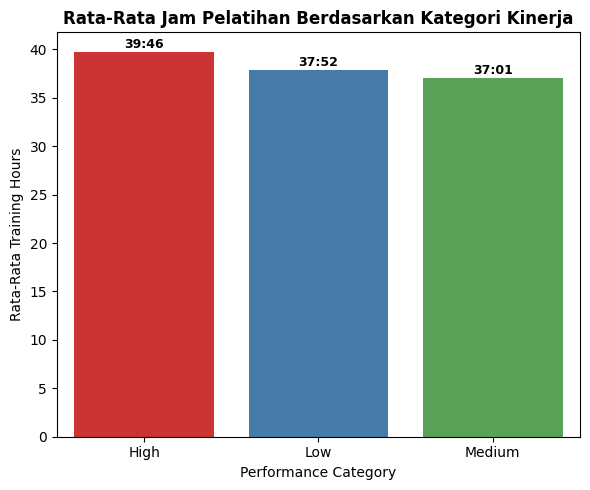

In [ ]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(data=analisis_1,
    x='performance_category',
    y='training_hours',
    order=analisis_1['performance_category'],
    palette='Set1',
    hue='performance_category',
    legend=False
)

for p, val in zip(ax.patches, analisis_1['training_hours(hm)']):
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2.,
        height + 0.1,
        val,
        ha='center', va='bottom',
        fontsize=9, fontweight='bold'
    )

plt.title('Rata-Rata Jam Pelatihan Berdasarkan Kategori Kinerja', fontsize=12, fontweight='bold')
plt.xlabel('Performance Category', fontsize=10)
plt.ylabel('Rata-Rata Training Hours', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import scipy.stats as stats

high_group = df_employee[df_employee['performance_category'] == 'High']['training_hours']
medium_group = df_employee[df_employee['performance_category'] == 'Medium']['training_hours']
low_group = df_employee[df_employee['performance_category'] == 'Low']['training_hours']

f_stat, p_value = stats.f_oneway(high_group, medium_group, low_group)

print(f"F-Statistic: {f_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

if p_value < 0.05:
    print("Hasil: H0 ditolak (Ada perbedaan yang signifikan antara rata-rata jam pelatihan terhadap kinerja karyawan)")
else:
    print("Hasil: H0 diterima (Tidak ada perbedaan yang signifikan antara rata-rata jam pelatihan terhadap kinerja karyawan)")

F-Statistic: 1.5372
P-Value: 0.2154
Hasil: H0 diterima (Tidak ada perbedaan yang signifikan antara rata-rata jam pelatihan terhadap kinerja karyawan)


**Analisis 2**: Apakah experience level berpengaruh terhadap jumlah proyek yang dapat diselesaikan?

In [ ]:
analisis_2 = df_employee.groupby('experience_level')['projects_completed'].mean().reset_index()
analisis_2 = analisis_2.sort_values(by='projects_completed', ascending=False)

print("--- Rata-Rata Projects Completed Berdasarkan Experience Level ---")
print(analisis_2[['experience_level', 'projects_completed']])

--- Rata-Rata Projects Completed Berdasarkan Experience Level ---
  experience_level  projects_completed
1              Mid               10.08
2           Senior                9.85
0           Junior                9.38


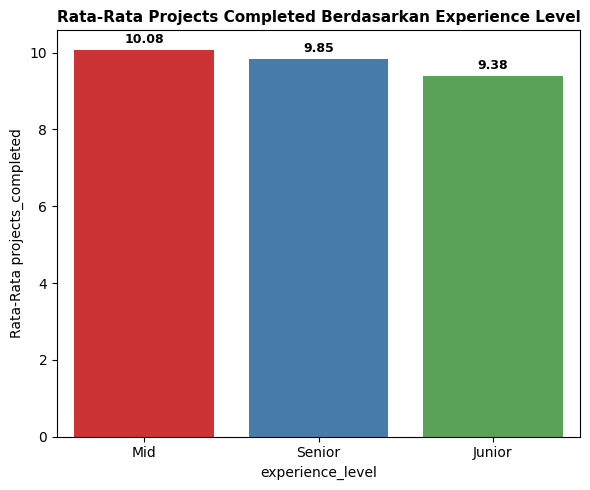

In [ ]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(data=analisis_2,
    x='experience_level',
    y='projects_completed',
    order=analisis_2['experience_level'],
    palette='Set1',
    hue='experience_level',
    legend=False
)

for p, val in zip(ax.patches, analisis_2['projects_completed']):
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2.,
        height + 0.1,
        f"{val:.2f}",
        ha='center', va='bottom',
        fontsize=9, fontweight='bold'
    )

plt.title('Rata-Rata Projects Completed Berdasarkan Experience Level', fontsize=11, fontweight='bold')
plt.xlabel('experience_level', fontsize=10)
plt.ylabel('Rata-Rata projects_completed', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
Junior = df_employee[df_employee['experience_level'] == 'Junior']['projects_completed']
Mid = df_employee[df_employee['experience_level'] == 'Mid']['projects_completed']
Senior = df_employee[df_employee['experience_level'] == 'Senior']['projects_completed']

f_stat, p_value = stats.f_oneway(Junior, Mid, Senior)

print(f"F-Statistic: {f_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

if p_value < 0.05:
    print("Hasil: H0 ditolak (Ada perbedaan yang signifikan antara rata-rata projects_completed terhadap experience level)")
else:
    print("Hasil: H0 diterima (Tidak ada perbedaan yang signifikan antara rata-rata projects_completed terhadap experience level)")

F-Statistic: 0.4143
P-Value: 0.6609
Hasil: H0 diterima (Tidak ada perbedaan yang signifikan antara rata-rata projects_completed terhadap experience level)


**B. Insight/Rekomendasi**

1. **Analisis 1**: Apakah ada pengaruh antara rata-rata jam pelatihan yang diberikan ke karyawan terhadap kinerja mereka?
  *   **Insight**: Ditemukan bahwa tidak ada perbedaan signifikan antara rata-rata jam pelatihan terhadap kategori kinerja (*Low, Medium, High*). Hal ini mengindikasi bahwa kuantitas jam pelatihan saja tidak otomatis mendongkrak level performa karyawan.
*  **Rekomendasi**:Berdasarkan insight tersebut, disarankan untuk meninjau kembali relevansi kurikulum pelatihan dan mengevaluasi metode post training agar tidak sekedar berfokus pada pencatatan kehadiran. Selain itu, manajemen perlu memperhatikan faktor-faktor lain yang terbukti berdampak langsung terhadap kinerja karyawan seperti beban kerja, kesesuaian *job desk*, serta efektivitas pengelolaan tim.

2. **Analisis 2**: Apakah experience level berpengaruh terhadap jumlah proyek yang dapat diselesaikan?
*   **Insight**: Ditemukan bahwa jumlah proyek yang diselesaikan oleh karyawan tingkat Junior, Mid, dan Senior cenderung mirip, sehingga tidak ada kelompok level tertentu yang mendominasi volume penyelesaian proyek. Namun, temuan ini mengindikasi bahwa fokus evaluasi bukan hanya dilihat dari kuantitas proyek, tetapi juga dari dampak dan skala tanggung jawab yang dipegang oleh masing-masing level
*   **Rekomendasi**: Berdasarkan insight tersebut, disarankan untuk melakukan peninjauan kembali terhadap beban kerja guna memastikan apakah distribusi pembagaian tugas sudah sesuai dengan levelnya, manajemen juga perlu mengevaluasi variabel performa kinerja lainnya untuk menganalisis kinerja karyawan secara lebih komperhensif.






